<a href="https://colab.research.google.com/github/pratikthawkar002-del/ML-Knowledge-Assistant-Project/blob/main/ML_Knowledge_Assistant_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==============================================================================
# PROJECT: Machine Learning Knowledge Assistant
# CONCEPTS: Unsupervised Learning (K-Means, PCA) & Supervised Learning (Logistic Regression)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics.pairwise import cosine_similarity
import ipywidgets as widgets
from IPython.display import display, clear_output

In [ ]:
# ------------------------------------------------------------------------------
# STEP 1 & 2: Problem Definition & Data Collection
# ------------------------------------------------------------------------------
df = pd.read_csv("master_ml_dataset.csv")
print("Step 2 - Total Dataset Rows Loaded:", len(df))

Step 2 - Total Dataset Rows Loaded: 644


In [ ]:
# ------------------------------------------------------------------------------
# STEP 3 & 4: Data Cleaning & Exploratory Data Analysis (EDA)
# ------------------------------------------------------------------------------
df = df.dropna(subset=["question", "answer"])
df = df.drop_duplicates(subset=["question"]).reset_index(drop=True)
print("Step 3 - Clean Dataset Rows:", len(df))
print("\nStep 4 - Dataset Sample:\n", df.head(3))

Step 3 - Clean Dataset Rows: 644

Step 4 - Dataset Sample:
                                             question  \
0  Define Machine Learning. Explain how it is dif...   
1  Differentiate between Artificial Intelligence,...   
2  Explain the concept of feature engineering wit...   

                                              answer  
0  Machine Learning is a subset of Artificial Int...  
1  1. Artificial Intelligence (AI): The broadest ...  
2  Feature Engineering is the process of selectin...  


In [ ]:
# ------------------------------------------------------------------------------
# STEP 5: Feature Engineering (Convert Text to Numbers using TF-IDF)
# ------------------------------------------------------------------------------
vectorizer = TfidfVectorizer(stop_words="english", max_features=1000)
X = vectorizer.fit_transform(df["question"])
print("\nStep 5 - TF-IDF Matrix Shape:", X.shape)


Step 5 - TF-IDF Matrix Shape: (644, 950)


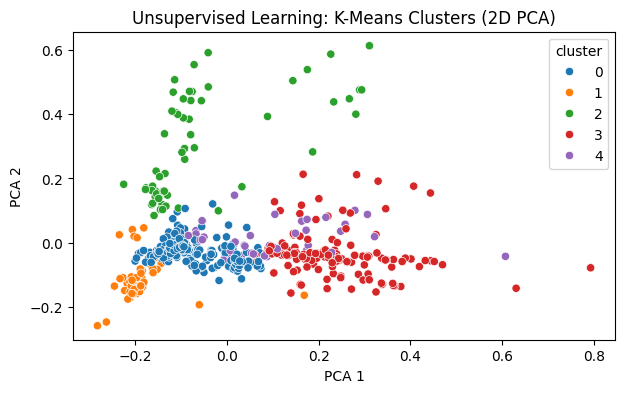

In [ ]:
# ------------------------------------------------------------------------------
# STEP 6 & 7A: Unsupervised Learning (K-Means Clustering & PCA Plot)
# ------------------------------------------------------------------------------
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X)

# 2D Visualization using PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(7, 4))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df["cluster"], palette="tab10")
plt.title("Unsupervised Learning: K-Means Clusters (2D PCA)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()



Step 8 - Supervised Model Accuracy: 86.05%

Classification Report:
               precision    recall  f1-score   support

           0       0.81      1.00      0.89        62
           1       1.00      0.67      0.80        12
           2       1.00      0.54      0.70        13
           3       0.91      0.91      0.91        32
           4       1.00      0.50      0.67        10

    accuracy                           0.86       129
   macro avg       0.94      0.72      0.79       129
weighted avg       0.88      0.86      0.85       129



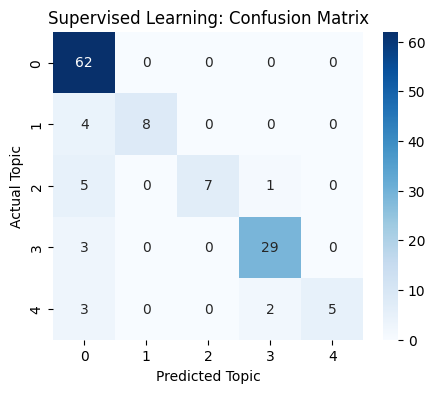

In [ ]:
# ------------------------------------------------------------------------------
# STEP 7B & 8: Supervised Learning (Classification & Evaluation)
# ------------------------------------------------------------------------------
y = df["cluster"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

classifier = LogisticRegression(max_iter=1000)
classifier.fit(X_train, y_train)

# Predict & Evaluate on Test Data
y_pred = classifier.predict(X_test)
print(f"\nStep 8 - Supervised Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Plot Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Supervised Learning: Confusion Matrix")
plt.xlabel("Predicted Topic")
plt.ylabel("Actual Topic")
plt.show()

In [ ]:
# ------------------------------------------------------------------------------
# STEP 9 & 10: Deployment & Monitoring (Simple Interactive Search Bar)
# ------------------------------------------------------------------------------
search_box = widgets.Text(
    placeholder="Type your ML question here...",
    description="Question:",
    layout=widgets.Layout(width="60%")
)
search_btn = widgets.Button(description="Get Answer", button_style="primary")
output = widgets.Output()

def search_answer(_):
    with output:
        clear_output()
        query = search_box.value.strip()
        if not query:
            print("Please type a question first.")
            return

In [ ]:
# 1. Convert query to TF-IDF vector
        query_vec = vectorizer.transform([query])

        # 2. Supervised: Predict topic cluster
        pred_cluster = classifier.predict(query_vec)[0]

        # 3. Unsupervised: Find closest matching question using Cosine Similarity
        scores = cosine_similarity(query_vec, X).flatten()
        best_index = np.argmax(scores)
        confidence = scores[best_index] * 100

        print("=" * 60)
        print("Your Question      :", query)
        print("Predicted Category : Cluster", pred_cluster, "(Supervised)")
        print(f"Match Confidence   : {confidence:.1f}% (Unsupervised)")
        print("Matched Question   :", df.loc[best_index, "question"])
        print("-" * 60)
        print("Answer:\n", df.loc[best_index, "answer"])
        print("=" * 60)

search_btn.on_click(search_answer)
search_box.on_submit(search_answer)

print("\nStep 9 - Search Bar Ready (Type a question below):")
display(widgets.HBox([search_box, search_btn]), output)


Step 9 - Search Bar Ready (Type a question below):


Output()